# Chapter 10: Clustering Techniques

## 1. Ringkasan Bab
Klastering (*clustering*) adalah rumpun algoritma pembelajaran mesin tanpa supervisi (*unsupervised learning*) yang bertujuan mengelompokkan observasi data ke dalam partisi atau klaster berdasarkan kemiripan pola fitur tanpa ketersediaan label target sebelumnya.

Materi inti yang dipelajari pada bab ini meliputi:
- **K-Means Clustering**: Pengelompokan partisi berbasis minimisasi variansi jarak titik ke titik pusat klaster (*centroids*), penentuan jumlah klaster optimal via metode *Elbow* dan analisis *Silhouette*.
- **Hierarchical Clustering (Agglomerative)**: Pembentukan hierarki klaster bertahap berbasis penggabungan bawah-ke-atas (*bottom-up*) dan visualisasi diagram percabangan (*dendrogram*).
- **Density-Based Spatial Clustering of Applications with Noise (DBSCAN)**: Pemisahan klaster berdasarkan densitas kepadatan lokal yang tangguh mendeteksi titik derau (*noise/outliers*) serta menangkap bentuk geometri klaster non-sferis.
- **Metrik Evaluasi Klastering**: Pengukuran kualitas pemisahan internal tanpa label menggunakan Silhouette Score dan Davies-Bouldin Index.
- **Perbandingan Karakteristik Algoritma**: Evaluasi perbedaan performa K-Means, Hierarchical, dan DBSCAN pada berbagai topologi data sintetis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_moons, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings

np.random.seed(2024)
warnings.filterwarnings('ignore')

print("Modul dan dependensi Chapter 10 berhasil dimuat.")

Modul dan dependensi Chapter 10 berhasil dimuat.


## 2. K-Means Clustering

Algoritma K-Means mempartisi $n$ data ke dalam $k$ klaster terpisah dengan meminimalkan nilai inersia atau Within-Cluster Sum of Squares (WCSS):
$$\text{WCSS} = \sum_{j=1}^{k} \sum_{\mathbf{x}_i \in C_j} \|\mathbf{x}_i - \boldsymbol{\mu}_j\|^2$$
Di mana $\boldsymbol{\mu}_j$ merupakan rata-rata koordinat titik pusat (*centroid*) pada klaster $C_j$.

Tahapan penentuan $k$ optimal:
1. **Metode Elbow**: Mencari titik belok grafik penurunan inersia WCSS terhadap pertambahan nilai $k$.
2. **Silhouette Analysis**: Mengukur seberapa dekat satu titik dengan anggota klaster sendiri dibanding klaster tetangga terdekat:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   Rentang nilai $s(i) \in [-1, 1]$. Nilai mendekati 1 menandakan pemisahan klaster yang sangat baik.

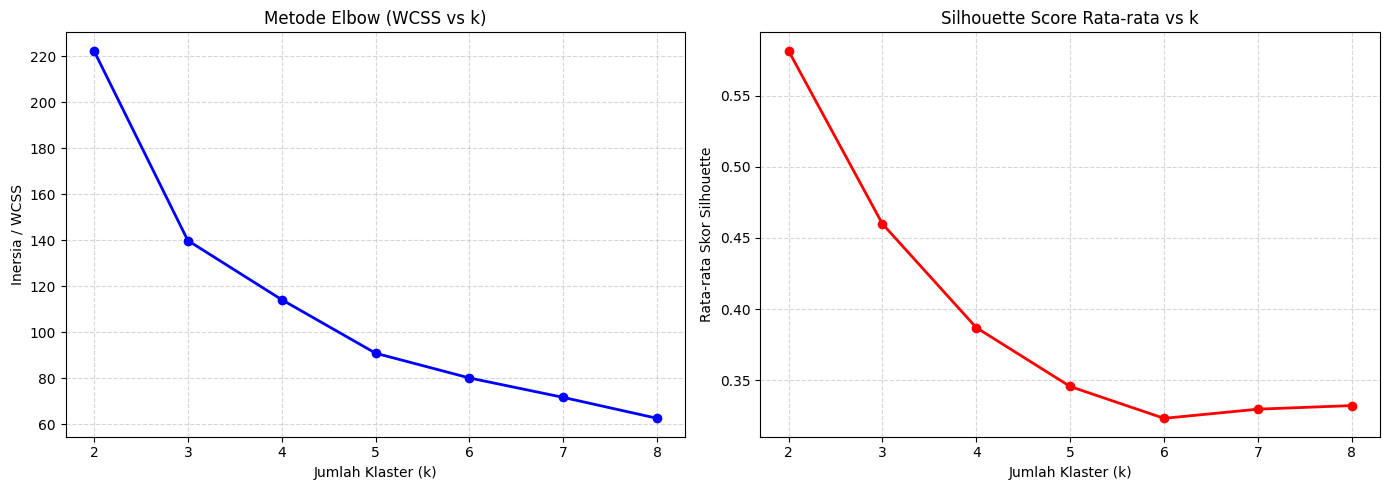

In [4]:
# Memuat Dataset Iris untuk Eksperimen K-Means
iris = load_iris()
X_iris = iris.data
feature_names = iris.feature_names

# Standarisasi fitur
scaler = StandardScaler()
X_iris_scaled = scaler.fit_transform(X_iris)

# Eksplorasi Jumlah Klaster Optimal (Elbow Method & Silhouette Scores)
k_range = range(2, 9)
wcss = []
sil_scores = []

for k in k_range:
    kmeans_eval = KMeans(n_clusters=k, random_state=2024, n_init=10)
    kmeans_eval.fit(X_iris_scaled)
    wcss.append(kmeans_eval.inertia_)
    sil_scores.append(silhouette_score(X_iris_scaled, kmeans_eval.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Elbow
ax1.plot(k_range, wcss, 'bo-', linewidth=2)
ax1.set_title('Metode Elbow (WCSS vs k)', fontsize=12)
ax1.set_xlabel('Jumlah Klaster (k)')
ax1.set_ylabel('Inersia / WCSS')
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot Silhouette Score
ax2.plot(k_range, sil_scores, 'ro-', linewidth=2)
ax2.set_title('Silhouette Score Rata-rata vs k', fontsize=12)
ax2.set_xlabel('Jumlah Klaster (k)')
ax2.set_ylabel('Rata-rata Skor Silhouette')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

=== Hasil Klastering K-Means (k=3) ===
Silhouette Score    : 0.4599
Davies-Bouldin Index: 0.8336 (nilai lebih rendah menandakan klaster lebih baik)


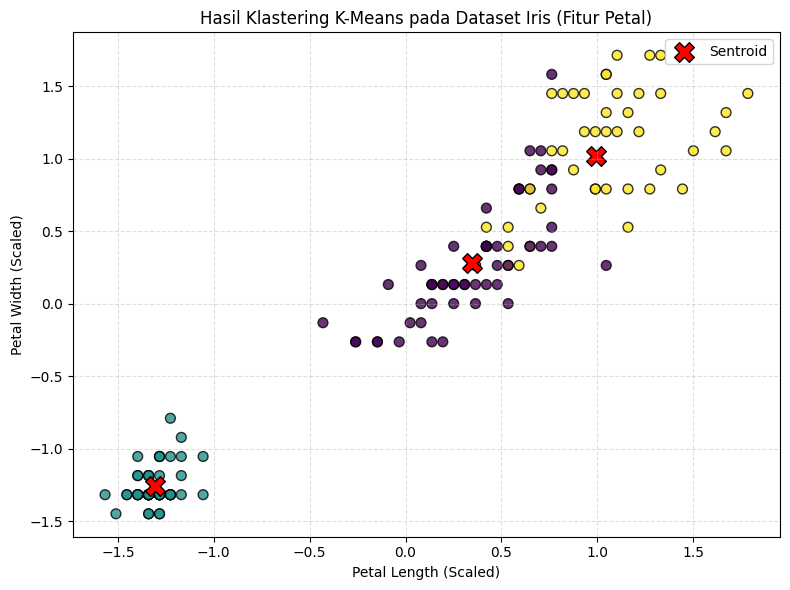

In [3]:
# Menjalankan K-Means dengan k=3
kmeans_final = KMeans(n_clusters=3, random_state=2024, n_init=10)
cluster_labels_km = kmeans_final.fit_predict(X_iris_scaled)

# Evaluasi Metrik Unsupervised
score_sil = silhouette_score(X_iris_scaled, cluster_labels_km)
score_db = davies_bouldin_score(X_iris_scaled, cluster_labels_km)

print("=== Hasil Klastering K-Means (k=3) ===")
print(f"Silhouette Score    : {score_sil:.4f}")
print(f"Davies-Bouldin Index: {score_db:.4f} (nilai lebih rendah menandakan klaster lebih baik)")

# Visualisasi Hasil Partisi K-Means (Petal Features)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_iris_scaled[:, 2],
    X_iris_scaled[:, 3],
    c=cluster_labels_km,
    cmap='viridis',
    s=50,
    edgecolors='k',
    alpha=0.8
)
# Menandai posisi sentroid
centroids = kmeans_final.cluster_centers_
plt.scatter(
    centroids[:, 2],
    centroids[:, 3],
    marker='X',
    s=200,
    color='red',
    edgecolors='black',
    label='Sentroid'
)

plt.title('Hasil Klastering K-Means pada Dataset Iris (Fitur Petal)', fontsize=12)
plt.xlabel('Petal Length (Scaled)')
plt.ylabel('Petal Width (Scaled)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 3. Hierarchical Agglomerative Clustering & Dendrogram

Metode aglomeratif menggabungkan pasangan klaster terdekat secara bertahap (*bottom-up*):
1. Setiap sampel data diawali sebagai satu klaster individual tersendiri.
2. Jarak kedekatan antar-klaster dihitung menggunakan kriteria keterkaitan (*linkage criteria*), seperti:
   - **Ward**: Meminimalkan kenaikan total variansi internal pasca-penggabungan.
   - **Complete**: Mengukur jarak maksimum antar-anggota klaster.
   - **Average**: Mengukur rata-rata jarak seluruh pasangan anggota klaster.
3. Struktur hirarkis divisualisasikan dalam bentuk pohon percabangan (*dendrogram*).

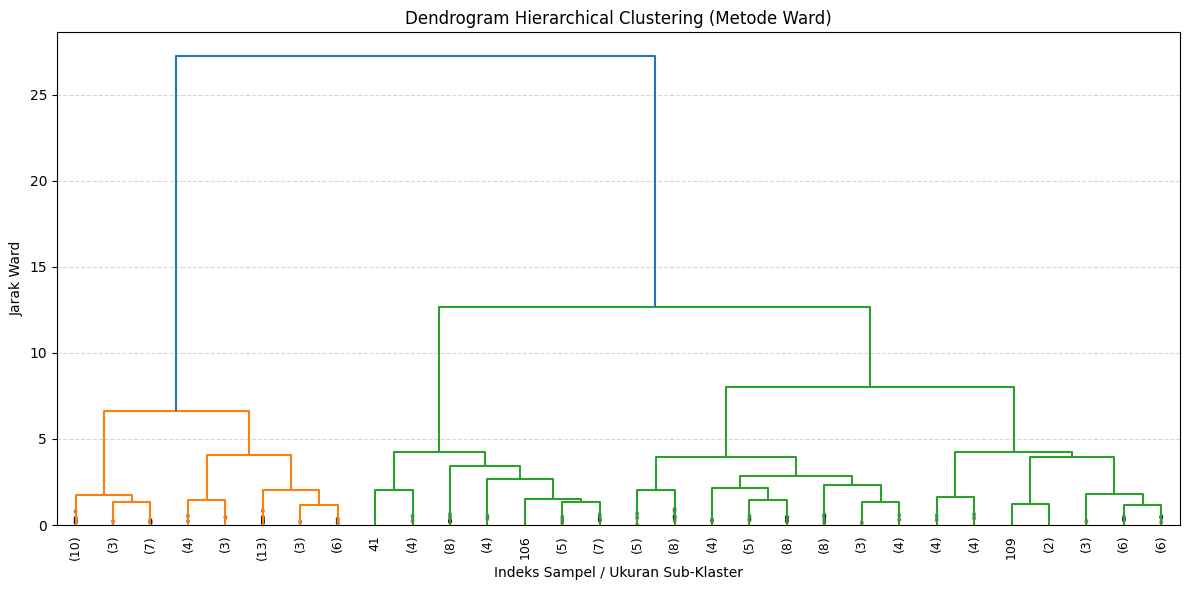

Silhouette Score (Hierarchical Ward): 0.4467


In [5]:
# Perhitungan Matriks Keterkaitan (Linkage Matrix) dengan Metode Ward
linkage_matrix = linkage(X_iris_scaled, method='ward')

# Visualisasi Dendrogram
plt.figure(figsize=(12, 6))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=9.,
    show_contracted=True
)
plt.title('Dendrogram Hierarchical Clustering (Metode Ward)', fontsize=12)
plt.xlabel('Indeks Sampel / Ukuran Sub-Klaster')
plt.ylabel('Jarak Ward')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Pelatihan Model AgglomerativeClustering (3 Klaster)
agg_clustering = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg_clustering.fit_predict(X_iris_scaled)

print(f"Silhouette Score (Hierarchical Ward): {silhouette_score(X_iris_scaled, agg_labels):.4f}")

## 4. Density-Based Spatial Clustering (DBSCAN)

DBSCAN mendefinisikan klaster berdasarkan kepadatan lokal titik pada ruang metrik:
- **Epsilon ($\epsilon$)**: Radius jarak maksimum lingkungan sekitar titik.
- **MinPts (`min_samples`)**: Jumlah minimum titik dalam radius $\epsilon$ untuk membentuk titik inti (*Core Point*).

Keunggulan DBSCAN dibanding K-Means:
1. Tidak membutuhkan asumsi penentuan jumlah klaster $k$ di awal.
2. Mampu menemukan klaster dengan geometri sembarang (misalnya bentuk bulan sabit/non-sferis).
3. Mengisolasi titik terpencil berdensitas rendah secara otomatis sebagai derau (*noise*, berlabel -1).

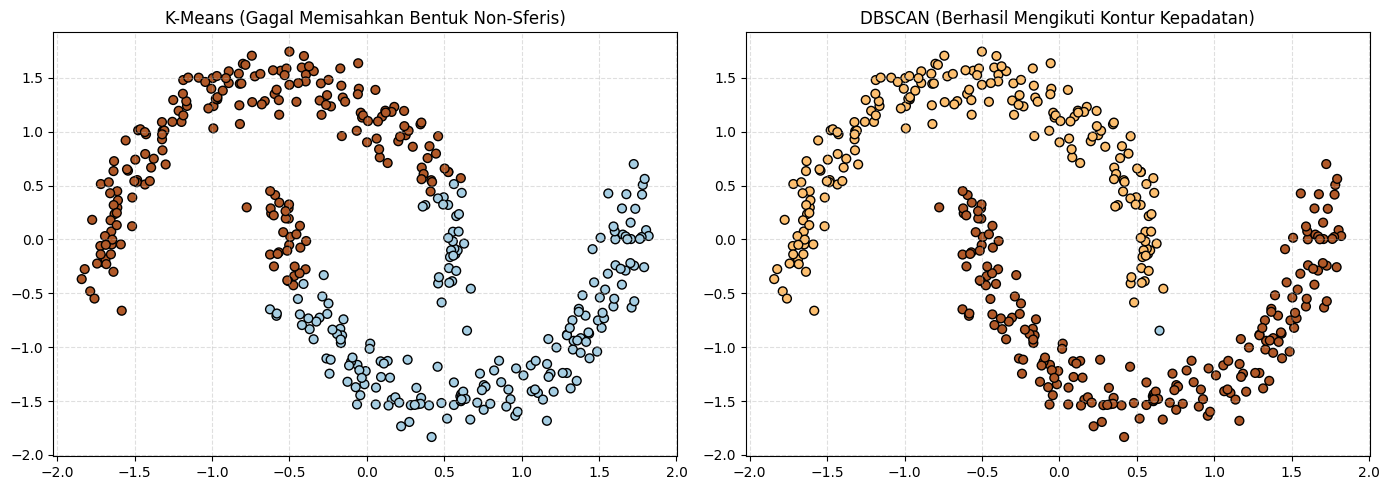

Jumlah klaster terdeteksi oleh DBSCAN: 2
Jumlah titik derau (noise points)    : 1


In [6]:
# Pembuatan Dataset Bentuk Bulan Sabit Bersarang (Non-Sferis)
X_moons, _ = make_moons(n_samples=400, noise=0.08, random_state=2024)
X_moons_scaled = StandardScaler().fit_transform(X_moons)

# 1. Menjalankan K-Means pada Data Non-Sferis
km_moons = KMeans(n_clusters=2, random_state=2024, n_init=10)
labels_km_moons = km_moons.fit_predict(X_moons_scaled)

# 2. Menjalankan DBSCAN pada Data Non-Sferis
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_db_moons = dbscan.fit_predict(X_moons_scaled)

# Komparasi Visual: K-Means vs DBSCAN pada Data Non-Linier
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=labels_km_moons, cmap='Paired', edgecolors='k', s=40)
ax1.set_title('K-Means (Gagal Memisahkan Bentuk Non-Sferis)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.4)

ax2.scatter(X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=labels_db_moons, cmap='Paired', edgecolors='k', s=40)
ax2.set_title('DBSCAN (Berhasil Mengikuti Kontur Kepadatan)', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print(f"Jumlah klaster terdeteksi oleh DBSCAN: {len(set(labels_db_moons)) - (1 if -1 in labels_db_moons else 0)}")
print(f"Jumlah titik derau (noise points)    : {np.sum(labels_db_moons == -1)}")

## 5. Komparasi Karakteristik Algoritma Klastering

Tabel berikut merangkum perbedaan aspek operasional antara K-Means, Hierarchical Clustering, dan DBSCAN:

| Parameter | K-Means | Hierarchical Agglomerative | DBSCAN |
| :--- | :--- | :--- | :--- |
| **Bentuk Geometri Klaster** | Sferis / Berbentuk Cembung | Bervariasi tergantung linkage | Sembarang / Bebas (*Arbitrary Shapes*) |
| **Spesifikasi Jumlah Klaster** | Wajib ditentukan di awal ($k$) | Wajib dipotong pada tingkat tertentu | Otomatis ditentukan berdasarkan densitas |
| **Ketahanan terhadap Outliers** | Sensitif terhadap derau/pencilan | Bergantung pada kriteria linkage | Sangat kuat (mengisolasi derau sebagai label -1) |
| **Skalabilitas Komputasi** | Cepat, efisien pada data besar $O(n)$ | Lambat pada dataset besar $O(n^3)$ | Efisien dengan pengindeksan spasial $O(n \log n)$ |
| **Parameter Kunci** | `n_clusters`, `init` | `n_clusters`, `linkage` | `eps`, `min_samples` |

## 6. Analisis dan Kesimpulan
1. **Partisi Sferis K-Means**: Algoritma K-Means bekerja sangat baik dalam memisahkan klaster cembung sferis seperti pada dataset Iris terstandarisasi, didukung oleh nilai Silhouette Score yang stabil pada $k=3$.
2. **Keterbatasan Asumsi Jarak**: K-Means gagal memisahkan struktur data melengkung (seperti dataset *Moons*) karena optimasi berbasis jarak garis lurus ke sentroid selalu menghasilkan partisi pembagi linier/datar.
3. **Fleksibilitas Densitas DBSCAN**: DBSCAN membuktikan keunggulannya dalam menangkap struktur data berdensitas non-linier dan secara otomatis memisahkan titik-titik anomali tanpa memerlukan asumsi jumlah klaster terlebih dahulu.